# Feature Space Breakdown
Load the 2019–2024 development cohort and audit the split between numerical and categorical risk drivers prior to sequential filtering.

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 110

data_path = "../data/synthetic_portfolio/train_portfolio_2019_2024.csv"
df = pd.read_csv(data_path)

target = "possession_flag"
id_cols = ["account_id", "default_date", "default_quarter", "default_year"]
feature_cols = [c for c in df.columns if c not in id_cols + [target]]

cat_cols = df[feature_cols].select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = df[feature_cols].select_dtypes(exclude=["object", "category"]).columns.tolist()

print(f"Development Cohort Dimensions : {df.shape[0]:,} defaulted accounts x {df.shape[1]} columns")
print(f"Candidate Feature Space       : {len(feature_cols)} features ({len(num_cols)} Numerical | {len(cat_cols)} Categorical)")

Development Cohort Dimensions : 61,048 defaulted accounts x 80 columns
Candidate Feature Space       : 75 features (49 Numerical | 26 Categorical)


## Target Variable Assessment
In IRB LGD / PPGD modelling, risk must be evaluated on both an account-weighted (volume) and exposure-weighted basis. Higher-balance, high-LTV loans exhibit higher litigation severity, causing exposure-weighted PPGD to sit above simple account-level PPGD.

In [37]:
total_accounts = len(df)
total_ead = df["current_balance"].sum()
total_arrears = df["arrears_balance"].sum()

vol_ppgd = df[target].mean() * 100
ead_ppgd = (df.loc[df[target] == 1, "current_balance"].sum() / total_ead) * 100
arr_ppgd = (df.loc[df[target] == 1, "arrears_balance"].sum() / total_arrears) * 100

summary_table = df.groupby(target).agg(
    Account_Count=("account_id", "count"),
    Total_EAD_GBP=("current_balance", "sum"),
    Mean_EAD_GBP=("current_balance", "mean"),
    Total_Arrears_GBP=("arrears_balance", "sum"),
    Mean_LTV=("current_ltv", "mean")
).reset_index()

summary_table["Outcome"] = summary_table[target].map({0: "0 - Cured / Retained", 1: "1 - Possessed"})
summary_table["Volume_Share_%"] = (summary_table["Account_Count"] / total_accounts * 100).round(2)
summary_table["Exposure_Share_%"] = (summary_table["Total_EAD_GBP"] / total_ead * 100).round(2)
summary_table["Total_EAD_GBP"] = summary_table["Total_EAD_GBP"].apply(lambda x: f"£{x/1e6:,.1f}M")
summary_table["Mean_EAD_GBP"] = summary_table["Mean_EAD_GBP"].apply(lambda x: f"£{x:,.0f}")
summary_table["Total_Arrears_GBP"] = summary_table["Total_Arrears_GBP"].apply(lambda x: f"£{x/1e6:,.1f}M")
summary_table["Mean_LTV"] = (summary_table["Mean_LTV"] * 100).round(1).astype(str) + "%" #type:ignore

display(summary_table[["Outcome", "Account_Count", "Volume_Share_%", "Total_EAD_GBP", "Exposure_Share_%", "Mean_EAD_GBP", "Total_Arrears_GBP", "Mean_LTV"]])
print(f"\n Account-Weighted (Volume) PPGD   : {vol_ppgd:.2f}%")
print(f" Exposure-Weighted (Monetary) PPGD: {ead_ppgd:.2f}% (+{ead_ppgd - vol_ppgd:.2f}% severity spread)")
print(f" Arrears-Weighted PPGD            : {arr_ppgd:.2f}%")

,Outcome,Account_Count,Volume_Share_%,Total_EAD_GBP,Exposure_Share_%,Mean_EAD_GBP,Total_Arrears_GBP,Mean_LTV
0,0 - Cured / Retained,56895,93.2,"£10,666.1M",92.09,"£187,470",£369.0M,66.8%
1,1 - Possessed,4153,6.8,£916.1M,7.91,"£220,580",£52.4M,75.0%



 Account-Weighted (Volume) PPGD   : 6.80%
 Exposure-Weighted (Monetary) PPGD: 7.91% (+1.11% severity spread)
 Arrears-Weighted PPGD            : 12.44%


## Temporal Non-Stationarity
Assess target stability and macroeconomic cyclicality across the 24-quarter development window (2019 Q1 – 2024 Q4). We plot quarterly default exposure (£M) alongside both Account-Weighted PPGD and Exposure-Weighted PPGD on a 4-Quarter Moving Average (4Q MA) to smooth court scheduling seasonality.

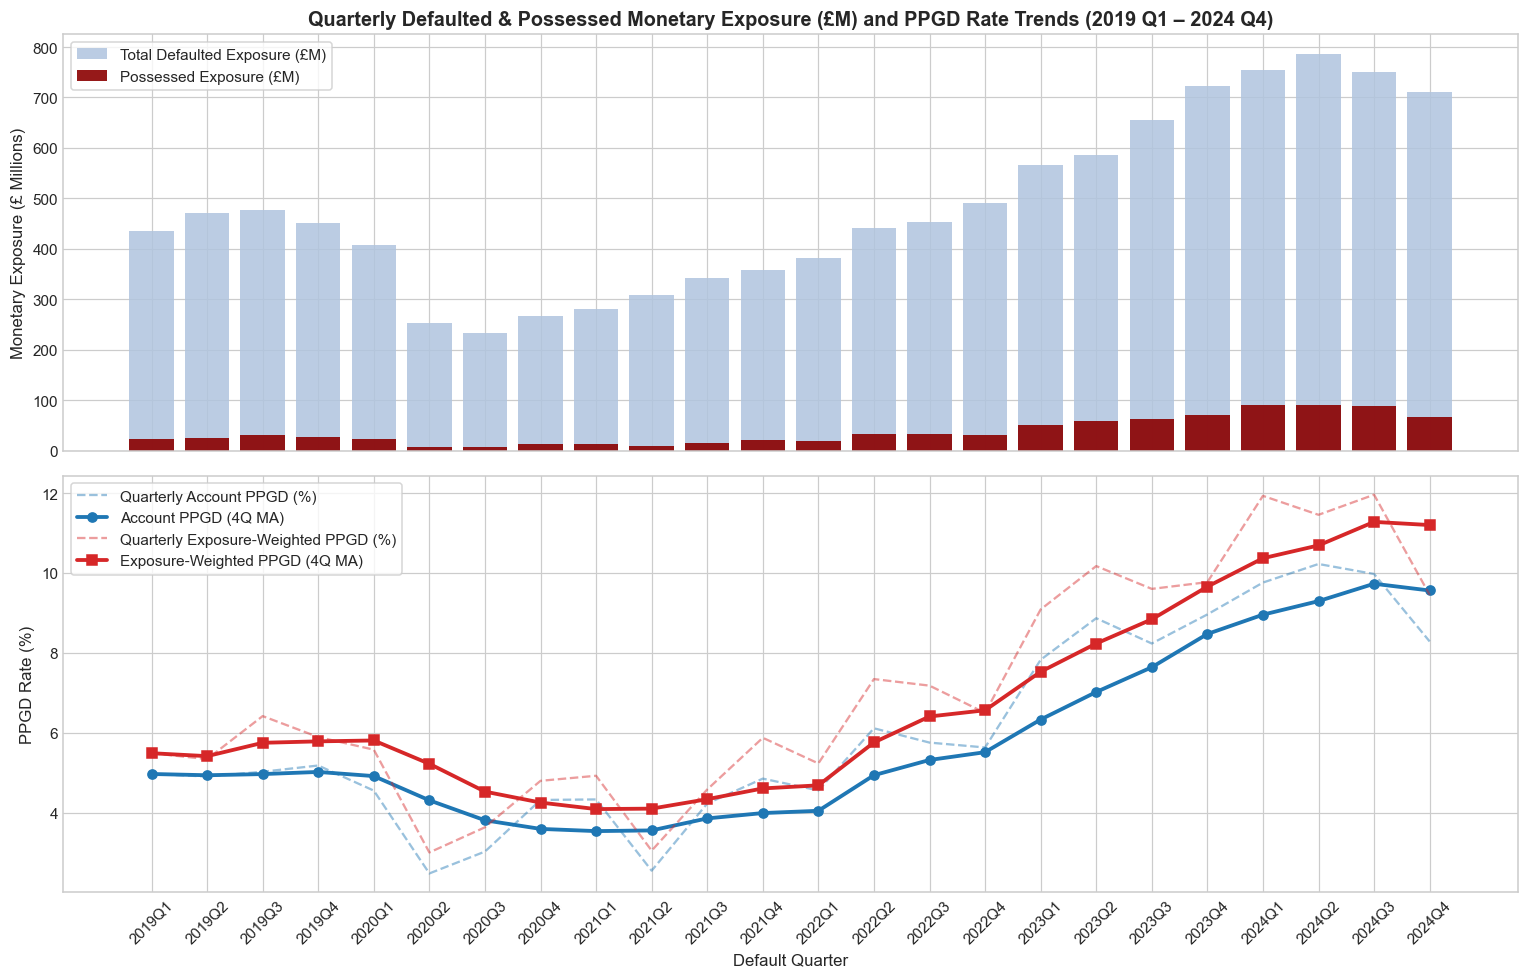

In [38]:
q_stats = df.groupby("default_quarter").apply(
    lambda g: pd.Series({
        "account_vol": len(g),
        "total_ead_m": g["current_balance"].sum() / 1e6,
        "possessed_ead_m": g.loc[g[target] == 1, "current_balance"].sum() / 1e6,
        "vol_ppgd_pct": g[target].mean() * 100,
        "ead_ppgd_pct": (g.loc[g[target] == 1, "current_balance"].sum() / g["current_balance"].sum()) * 100
    })
,include_groups = False).reset_index() # type: ignore

q_stats["vol_4q_ma"] = q_stats["vol_ppgd_pct"].rolling(4, min_periods=1).mean()
q_stats["ead_4q_ma"] = q_stats["ead_ppgd_pct"].rolling(4, min_periods=1).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Top Panel: Monetary Exposure at Default (£M) vs Possessed Exposure (£M)
ax1.bar(q_stats["default_quarter"], q_stats["total_ead_m"], color="#b0c4de", label="Total Defaulted Exposure (£M)", alpha=0.85)
ax1.bar(q_stats["default_quarter"], q_stats["possessed_ead_m"], color="#8b0000", label="Possessed Exposure (£M)", alpha=0.9)
ax1.set_ylabel("Monetary Exposure (£ Millions)", fontsize=11)
ax1.set_title("Quarterly Defaulted & Possessed Monetary Exposure (£M) and PPGD Rate Trends (2019 Q1 – 2024 Q4)", fontsize=13, fontweight="bold")
ax1.legend(loc="upper left", frameon=True)

# Bottom Panel: Volume PPGD vs Monetary Exposure PPGD (Quarterly & 4Q Moving Average)
ax2.plot(q_stats["default_quarter"], q_stats["vol_ppgd_pct"], color="#1f77b4", linestyle="--", alpha=0.45, label="Quarterly Account PPGD (%)")
ax2.plot(q_stats["default_quarter"], q_stats["vol_4q_ma"], color="#1f77b4", linewidth=2.5, marker="o", label="Account PPGD (4Q MA)")
ax2.plot(q_stats["default_quarter"], q_stats["ead_ppgd_pct"], color="#d62728", linestyle="--", alpha=0.45, label="Quarterly Exposure-Weighted PPGD (%)")
ax2.plot(q_stats["default_quarter"], q_stats["ead_4q_ma"], color="#d62728", linewidth=2.5, marker="s", label="Exposure-Weighted PPGD (4Q MA)")

ax2.set_ylabel("PPGD Rate (%)", fontsize=11)
ax2.set_xlabel("Default Quarter", fontsize=11)
ax2.legend(loc="upper left", frameon=True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Data Quality Audit
Before executing sequential feature selection in Notebook 02, we audit the 75 candidate features for:
1. **Validity:** Zero-variance (constant) columns across numerical and categorical features.
2. **Completeness:** Variables exceeding the 5.0% missing value threshold**.
3. **Categorical Concentration:** Categorical variables where a single dominant class holds >95% of accounts (leaving minority classes <5% and statistically unstable).
4. **Numerical Outliers:** Extreme tail inspection at the 1st and 99th percentiles prior to Winsorization.

In [39]:
# 1. Validity Check
zero_var_cols = [c for c in feature_cols if df[c].nunique(dropna=True) <= 1]
print(f"VALIDITY CHECK     : Found {len(zero_var_cols)} zero-variance features -> {zero_var_cols}")

# 2. Completeness Check (>5% missingness)
missing_pct = (df[feature_cols].isnull().mean() * 100).round(2)
high_missing = missing_pct[missing_pct > 5.0].to_dict()
print(f"COMPLETENESS CHECK : Found {len(high_missing)} features exceeding 5% missingness -> {high_missing}")

# 3. Categorical Concentration Check (Dominant category > 95% / Minority tail < 5%)
concentrated_cats = {}
for c in [col for col in cat_cols if col not in zero_var_cols]:
    top_share = df[c].value_counts(normalize=True, dropna=True).iloc[0] * 100
    if top_share > 95.0:
        concentrated_cats[c] = f"{top_share:.2f}% in top class"
print(f"CONCENTRATION CHECK: Found {len(concentrated_cats)} over-concentrated categoricals (>95% dominant) -> {concentrated_cats}")

# 4. Numerical Outlier Profile (1% vs 99% Quantiles on Key Risk Drivers)
key_num = ["current_ltv", "months_in_arrears", "arrears_balance", "credit_score", "debt_to_income_ratio", "current_balance"]
outlier_summary = df[key_num].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]).T[["mean", "std", "min", "1%", "50%", "99%", "max"]].round(2)
print("\nNUMERICAL TAIL & OUTLIER AUDIT (1% and 99% Winsorization Bounds):")
display(outlier_summary)

VALIDITY CHECK     : Found 2 zero-variance features -> ['currency_denomination', 'legacy_system_constant_id']
COMPLETENESS CHECK : Found 2 features exceeding 5% missingness -> {'legacy_affordability_score': 14.17, 'secondary_employer_tenure_m': 21.83}
CONCENTRATION CHECK: Found 3 over-concentrated categoricals (>95% dominant) -> {'shared_ownership_scheme': '97.60% in top class', 'Guarantor_Backed_Flag': '96.78% in top class', 'staff_mortgage_indicator': '98.86% in top class'}

NUMERICAL TAIL & OUTLIER AUDIT (1% and 99% Winsorization Bounds):


,mean,std,min,1%,50%,99%,max
current_ltv,0.67,0.14,0.19,0.38,0.67,1.01,1.27
months_in_arrears,7.14,4.66,3.00,3.00,5.00,24.00,24.00
arrears_balance,6903.51,6868.37,185.46,760.08,4736.16,34212.96,112780.68
credit_score,500.69,88.70,180.00,293.00,500.00,706.00,820.00
debt_to_income_ratio,4.83,4.04,0.27,0.81,3.68,20.51,70.61
current_balance,189722.20,100656.50,21394.38,52155.96,167534.94,528568.13,1287767.08


## Categorical Risk Segmentation
Verify that key categorical risk drivers (`litigation_status` and `forbearance_type`) exhibit monotonic rank-ordering across both account volume and monetary exposure.

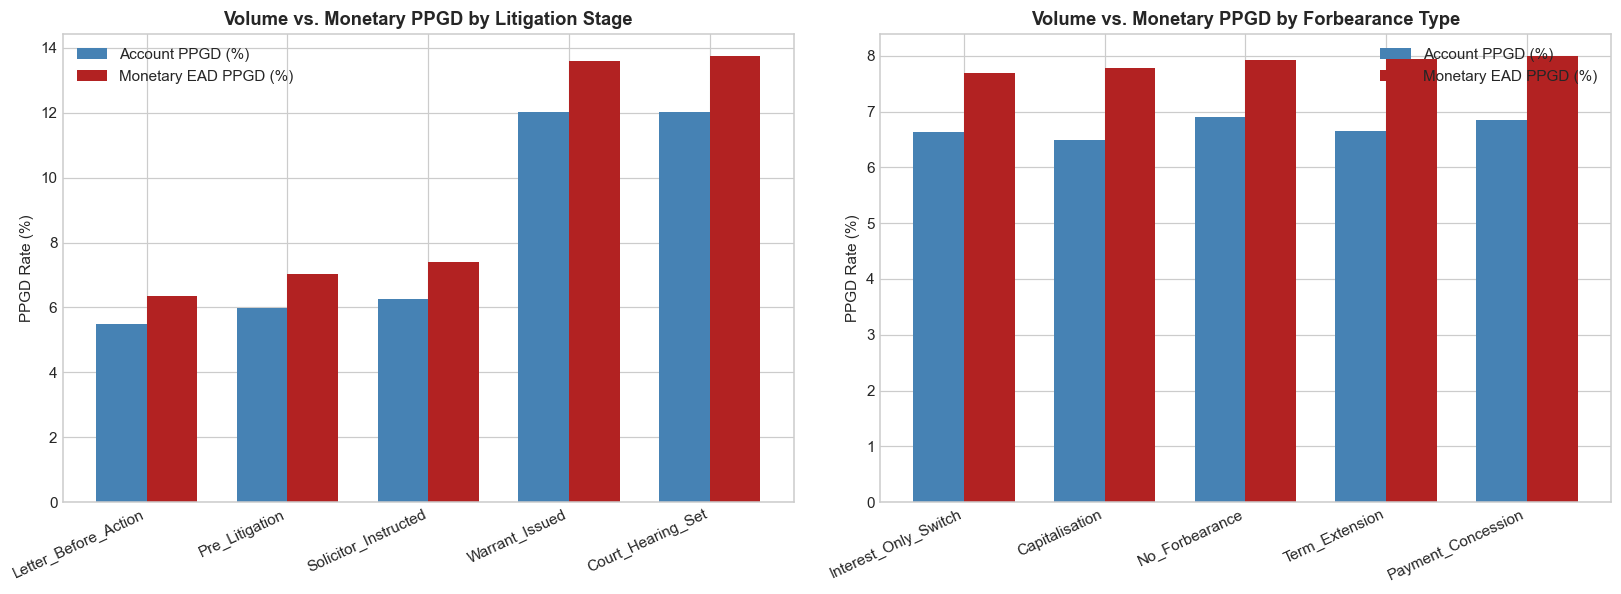

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for ax, col, title in zip(axes, ["litigation_status", "forbearance_type"], ["Litigation Stage", "Forbearance Type"]):
    seg = df.groupby(col).apply(
        lambda g: pd.Series({
            "Account_PPGD_%": g[target].mean() * 100,
            "Exposure_PPGD_%": (g.loc[g[target] == 1, "current_balance"].sum() / g["current_balance"].sum()) * 100
        })
    ,include_groups = False).sort_values("Exposure_PPGD_%") #type: ignore
    
    x = np.arange(len(seg))
    width = 0.36
    ax.bar(x - width/2, seg["Account_PPGD_%"], width, label="Account PPGD (%)", color="#4682b4")
    ax.bar(x + width/2, seg["Exposure_PPGD_%"], width, label="Monetary EAD PPGD (%)", color="#b22222")
    ax.set_xticks(x)
    ax.set_xticklabels(seg.index, rotation=25, ha="right")
    ax.set_ylabel("PPGD Rate (%)")
    ax.set_title(f"Volume vs. Monetary PPGD by {title}", fontweight="bold")
    ax.legend()

plt.tight_layout()
plt.show()